# Experiment 9: Model Validation and Explainability
**Aim:** To evaluate and interpret machine learning models using cross-validation, calibration and explainability techniques.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
sns.set_style("whitegrid")
COLS = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv("pima-indians-diabetes.csv", names=COLS)
print("Dataset shape:", df.shape)
df.head()
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score

Dataset shape: (768, 9)


In [2]:
X = df.drop(columns=["Outcome"]); y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
model = RandomForestClassifier(n_estimators=200, random_state=42)
scores = cross_val_score(model, X, y, cv=5)
print("5-fold CV accuracy scores:", np.round(scores, 3))
print(f"Mean CV accuracy = {scores.mean():.3f} (+/- {scores.std():.3f})")
model.fit(X_train, y_train)
print("Held-out test accuracy:", round(accuracy_score(y_test, model.predict(X_test)), 3))

5-fold CV accuracy scores: [0.747 0.74  0.753 0.824 0.765]
Mean CV accuracy = 0.766 (+/- 0.030)


Held-out test accuracy: 0.747


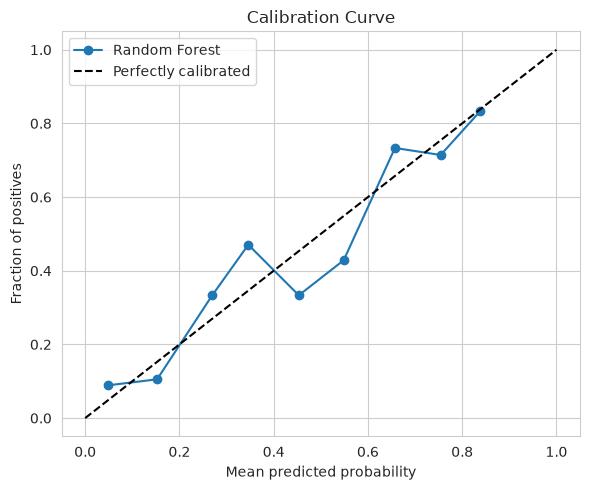

In [3]:
# Calibration curve: are predicted probabilities trustworthy?
prob = model.predict_proba(X_test)[:,1]
frac_pos, mean_pred = calibration_curve(y_test, prob, n_bins=10)
plt.figure(figsize=(6,5))
plt.plot(mean_pred, frac_pos, marker="o", label="Random Forest")
plt.plot([0,1],[0,1],"k--", label="Perfectly calibrated")
plt.xlabel("Mean predicted probability"); plt.ylabel("Fraction of positives")
plt.title("Calibration Curve"); plt.legend()
plt.tight_layout(); plt.savefig("images/fig1_calibration.png", dpi=130, bbox_inches="tight"); plt.show()

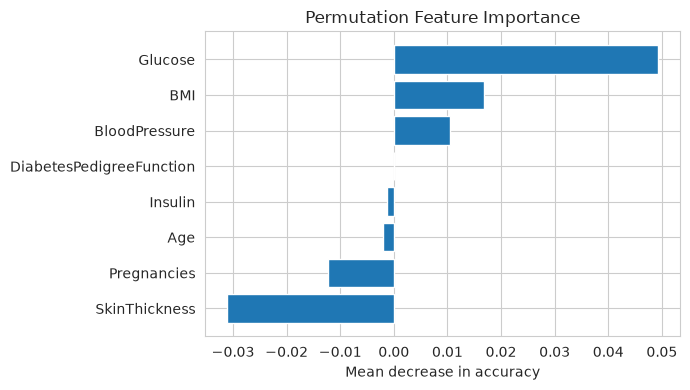

In [4]:
# Permutation importance: which features drive the model?
imp = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=42)
order = np.argsort(imp.importances_mean)
plt.figure(figsize=(7,4))
plt.barh(np.array(X.columns)[order], imp.importances_mean[order])
plt.xlabel("Mean decrease in accuracy"); plt.title("Permutation Feature Importance")
plt.tight_layout(); plt.savefig("images/fig2_importance.png", dpi=130, bbox_inches="tight"); plt.show()

## Key Observations
- 5-fold cross-validation gives a stable, trustworthy accuracy estimate.
- The calibration curve shows predicted probabilities are reasonably reliable.
- Permutation importance identifies Glucose, BMI and Age as the most influential features - consistent with medical intuition.